# Lab 5: Identification and Removal of Outliers for Improving Data Quality

In [1]:
import pandas as pd
import numpy as np 
from scipy import stats
import seaborn as sns
from sklearn.preprocessing import RobustScaler

from sklearn.datasets import load_breast_cancer

data=load_breast_cancer(as_frame=True).frame[['mean radius','mean area']].dropna()
df=pd.DataFrame(data)
df

,mean radius,mean area
0,17.99,1001.0
1,20.57,1326.0
2,19.69,1203.0
3,11.42,386.1
4,20.29,1297.0
...,...,...
564,21.56,1479.0
565,20.13,1261.0
566,16.60,858.1
567,20.60,1265.0


## Discover Outlier with boxplot

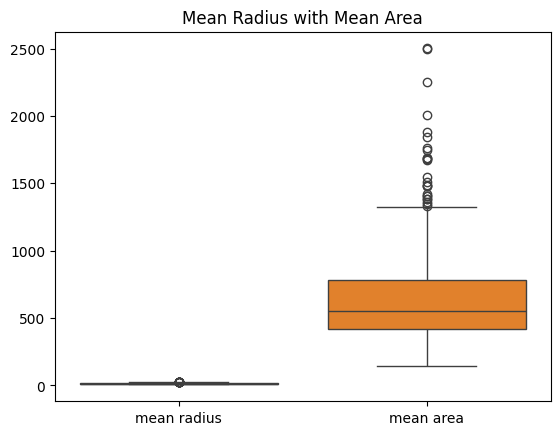

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# sns.boxplot(x='mean radius', y='mean area', data=df)

sns.boxplot(df)
# plt.boxplot(x='mean radius', y='mean area', data=df) 
plt.title("Mean Radius with Mean Area")
plt.show()

## Identify Outliers Using Z-score

In [3]:
z_scores = np.abs(stats.zscore(df))
outliers_z= (z_scores >3)
outliers_z

array([[False, False],
       [False, False],
       [False, False],
       ...,
       [False, False],
       [False, False],
       [False, False]], shape=(569, 2))

## IQR method

In [4]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outlier_iqr = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR)))
outlier_iqr

,mean radius,mean area
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
564,False,True
565,False,False
566,False,False
567,False,False


## Remove outliers

In [5]:
df_no_outliers = df[~((df < (Q1 - 1.5 * IQR)) |(df > (Q3 + 1.5 * IQR))).any(axis=1)]
df_no_outliers

,mean radius,mean area
0,17.99,1001.0
1,20.57,1326.0
2,19.69,1203.0
3,11.42,386.1
4,20.29,1297.0
...,...,...
562,15.22,716.9
565,20.13,1261.0
566,16.60,858.1
567,20.60,1265.0


## Replace Outliters with Median

In [6]:
df_replace_median= df.copy()
for col in df.columns:
    median = df[col].median()
    df_replace_median[col] = np.where(outlier_iqr[col], median, df[col])

df_replace_median

,mean radius,mean area
0,17.99,1001.0
1,20.57,1326.0
2,19.69,1203.0
3,11.42,386.1
4,20.29,1297.0
...,...,...
564,21.56,551.1
565,20.13,1261.0
566,16.60,858.1
567,20.60,1265.0


## Cap Outliers (winsorization)

In [7]:
df_winsorized = df.copy()
for col in df.columns:
    lower_limit = Q1[col] - 1.5 * IQR[col]
    upper_limit = Q3[col] + 1.5 * IQR[col]
    df_winsorized[col] = np.where(df[col] < lower_limit, lower_limit, df[col])
    df_winsorized[col] = np.where(df_winsorized[col] > upper_limit, upper_limit, df_winsorized[col])

df_winsorized

,mean radius,mean area
0,17.99,1001.0
1,20.57,1326.0
2,19.69,1203.0
3,11.42,386.1
4,20.29,1297.0
...,...,...
564,21.56,1326.3
565,20.13,1261.0
566,16.60,858.1
567,20.60,1265.0


## Log Transformation (only for positive values)

In [8]:
df_log=df.copy()
df_log['Log Mean Area'] = np.log(df_log['mean area'])
df_log

,mean radius,mean area,Log Mean Area
0,17.99,1001.0,6.908755
1,20.57,1326.0,7.189922
2,19.69,1203.0,7.092574
3,11.42,386.1,5.956096
4,20.29,1297.0,7.167809
...,...,...,...
564,21.56,1479.0,7.299121
565,20.13,1261.0,7.139660
566,16.60,858.1,6.754721
567,20.60,1265.0,7.142827


## Robust Scaling
### s= (X - Median)/IQR

In [9]:
scaler= RobustScaler()
df_scaled= pd.DataFrame(scaler.fit_transform(df), columns=df.columns)
df_scaled

,mean radius,mean area
0,1.132353,1.241446
1,1.764706,2.138245
2,1.549020,1.798841
3,-0.477941,-0.455298
4,1.696078,2.058223
...,...,...
564,2.007353,2.560430
565,1.656863,1.958885
566,0.791667,0.847130
567,1.772059,1.969923
